# comparing_model7 — the Enformer-grid stratum ladder, with EpiBERT

A standalone remake of **`IGVF_meeting_figures2` figure 3b** (`panel3b_ladder_enformer`), with one
new arm added to the ladder: **EpiBERT**, from
`joint_playground/model_out/epibert_gm12878_rampage_test_outputs.npy`.

Everything the original figure got from `igvf_arms.py` and
`igvf_meeting_figures2_analysis.py` — the arm registry, the colours, the AUROC engine, the
plotting — is **inlined below**. This notebook imports no project-local figure module and writes
nothing to disk.

## The ladder, in one table

Every rung uses the same class definition — "GM12878 CAGE above the noise floor" vs "below it" —
the same AUROC and the same region-level bootstrap. Each rung adds **exactly one** restriction to
the rung above it, so every rung is a strict subset of the one before.

| rung | positives | negatives | what it adds |
|---|---|---|---|
| **R0 · all bins** | any allowed bin, CAGE ≥ 1.0 | any allowed bin, CAGE < 0.2 | — ("is there a peak here") |
| **R1 · promoters** | R0 ∩ protein-coding TSS | R0 ∩ protein-coding TSS | element type matched on both sides |
| **R2 · + disagreement** | R1 ∩ cross-CT average **low** (< p50) | R1 ∩ cross-CT average **high** (≥ p90) | the generic expectation points the *wrong* way |
| **R3 · + accessibility** | R2 ∩ open | R2 ∩ closed | ATAC confirms each call |

The null falling to exactly 0.0 on R2/R3 is what says the last two rungs measure reliance on the
generic cross-cell-type shortcut, not task difficulty.

## What is read and what is computed

| | source | why |
|---|---|---|
| the 11 original arms' AUROCs + CIs | `IGVF_meeting_figures2_cache/ladder_enformer.parquet` | already built; rescoring them changes nothing |
| the four rungs' **index arrays** | rebuilt here from the source stores | the cache keeps only the rungs' *counts*, and a new arm cannot be scored without the indices |
| EpiBERT's AUROCs + CIs | computed here | the whole point |

The rebuild costs ~90 s, almost all of it the `labels.zarr` slice and the ATAC npz. Two gates make
it safe to mix a freshly-computed arm into cached numbers: the rebuilt rungs must match the cached
rung counts exactly, and `[null] cross-CT average` rescored from source must reproduce its cached
AUROC **and** its cached bootstrap interval. If both hold, the new arm is on the same ruler as the
cached ones.

In [1]:
# ============================================================================
# §0 - the shared engine: arm registry, palette, AUROC, bootstrap.
# Inlined from igvf_arms.py + igvf_meeting_figures2_analysis.py so this notebook
# has no project-local figure dependency. Nothing here is written to disk.
# ============================================================================
import json
import sys
import textwrap
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

N_BOOT = 200          # region-level bootstrap draws per (arm, rung)
BOOT_SEED = 0         # fresh rng per (arm, rung), so CIs do not depend on arm order

# --- family base hues --------------------------------------------------------
# Colour convention (set by the presenter, 2026-09-09):
#     cis-Mamba   green      Borzoi      blue
#     Enformer    red        AlphaGenome gold
#     ChromBPNet  purple     references  grey
# Arms inside one family are shades of that family's hue, darkest = the base or
# headline model, lighter = further from it. Identity never rests on colour alone:
# every bar carries an axis label and a printed value.
#
# EpiBERT is new to this notebook and belongs to no existing family, so it takes
# the one unclaimed slot in that convention: teal.
C_OURS = '#177A3B'   # cis-Mamba (this work)
C_ENF = '#A32316'    # Enformer family
C_AG = '#C9930A'     # AlphaGenome
C_EPI = '#0F8C8C'    # EpiBERT
C_REF = '#6B7280'    # measurements / nulls / chance -- never a model


@dataclass(frozen=True)
class Arm:
    id: str
    label: str
    family: str
    color: str
    hidden: bool = False        # scored and cached, but drawn by no panel


def _a(id, label, family, color, hidden=False):
    return Arm(id, label, family, color, hidden)


# Only the Enformer-grid arms: this notebook draws one panel, so the Borzoi-grid,
# eQTL and dsQTL arms of the original registry have nothing to be on. Order here
# is the canonical order; the panel itself reorders models by R3 and pins the
# reference rows to the top.
ARMS = [
    _a('mamba_1ct', 'cis-Mamba (1 cell type)', 'ours', '#177A3B'),
    _a('mamba_nopre', 'cis-Mamba (no pretraining)', 'ours', '#63BF82'),
    _a('mamba_8ct', 'cis-Mamba (8 cell types)', 'ours', '#9BD9AE'),

    _a('enformer_pre', 'Enformer (pretrained)', 'enformer', '#A32316'),
    # Two 1-cell-type retrained Enformers were run, at 768 and 1536 channels. Only
    # the 1536ch one is shown, and it is labelled plainly as the 1-CT retrain -- the
    # width is an implementation detail the audience does not need. The 768ch run
    # stays in the cache and stays registered here; `hidden` only removes it from
    # the panel.
    _a('enformer_n1', 'Enformer (retrained, 1 CT, 768ch)', 'enformer', '#E2603F', hidden=True),
    _a('enformer_n1_1536', 'Enformer (retrained, 1 CT)', 'enformer', '#C93B22'),
    _a('enformer_n16', 'Enformer (retrained, 16 CTs)', 'enformer', '#F0907A'),
    _a('enformer_n42', 'Enformer (retrained, 42 CTs)', 'enformer', '#F8BFB2'),

    _a('alphagenome', 'AlphaGenome', 'alphagenome', '#C9930A'),

    # NEW. Predicts GM12878 RAMPAGE rather than CAGE -- a different assay of the
    # same quantity. AUROC is rank-based, so being in other units costs it nothing;
    # see the caveat under §2.
    _a('epibert', 'EpiBERT (GM12878 RAMPAGE)', 'epibert', C_EPI),

    # References. Neither is a model; both are read against the model rows.
    _a('null_avg', '[null] cross-CT average', 'reference', C_REF),
    _a('acc_atac', 'GM12878 ATAC (measured)', 'reference', C_REF),
]
BY_ID = {a.id: a for a in ARMS}


def label(arm_id):
    return BY_ID[arm_id].label


def color(arm_id):
    return BY_ID[arm_id].color


mpl.rcParams.update({
    'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12.5,
    'xtick.labelsize': 10.5, 'ytick.labelsize': 10.5, 'legend.fontsize': 10.5,
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 0.9, 'axes.edgecolor': '#444444', 'text.color': '#222222',
    'axes.labelcolor': '#222222', 'xtick.color': '#444444', 'ytick.color': '#444444',
    'figure.facecolor': 'white',
})
INK, INK2 = '#222222', '#555555'


# ---------------------------------------------------------------------------
# AUROC from value codes: algebraically identical to the rank-based reference
# implementation (0.5 credit for ties) but ~50x cheaper inside a bootstrap,
# because the single sort is hoisted out of the loop.
# ---------------------------------------------------------------------------
def to_codes(vp, vn):
    """Map both classes onto a shared sorted-value index. One sort per arm-rung."""
    uniq, codes = np.unique(np.concatenate([vp, vn]), return_inverse=True)
    codes = np.asarray(codes).ravel()
    return codes[:len(vp)], codes[len(vp):], len(uniq)


def auroc_codes(cp_codes, cn_codes, n_uniq):
    """Mann-Whitney AUROC from value codes, with 0.5-credit tie handling."""
    cp = np.bincount(cp_codes, minlength=n_uniq).astype(np.float64)
    cn = np.bincount(cn_codes, minlength=n_uniq).astype(np.float64)
    below = np.concatenate([[0.0], np.cumsum(cn)[:-1]])
    return float((cp * below).sum() + 0.5 * float((cp * cn).sum())) / (cp.sum() * cn.sum())


def group_by_region(mask, rid):
    """Bin indices ordered by region, plus per-region slices -- makes the bootstrap cheap."""
    idx = np.flatnonzero(mask)
    r = rid[idx]
    o = np.argsort(r, kind='stable')
    idx, r = idx[o], r[o]
    regs, starts = np.unique(r, return_index=True)
    stops = np.append(starts[1:], len(idx))
    return idx, np.stack([starts, stops], axis=1), regs


def make_rung(name, subtitle, pos_mask, neg_mask, rid):
    pi, ps, pr = group_by_region(pos_mask, rid)
    ni, ns, nr = group_by_region(neg_mask, rid)
    return dict(name=name, subtitle=subtitle, pi=pi, ps=ps, n_preg=len(pr),
                ni=ni, ns=ns, n_nreg=len(nr), n_pos=len(pi), n_neg=len(ni))


def _draw(codes, sl, n_reg, rng):
    pick = rng.integers(0, n_reg, n_reg)
    return np.concatenate([codes[sl[k, 0]:sl[k, 1]] for k in pick])


def score_rung(pv, rung, n_boot=N_BOOT, seed=BOOT_SEED):
    """Point estimate + region-level bootstrap CI for one arm on one rung.

    The bootstrap resamples *regions*, not bins: neighbouring bins inside a region
    are anything but independent, so a bin-level interval would be far too tight.
    """
    vp, vn = pv[rung['pi']], pv[rung['ni']]
    cp, cn, U = to_codes(vp, vn)
    a0 = auroc_codes(cp, cn, U)
    if n_boot == 0:
        return a0, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    bo = np.empty(n_boot)
    for b in range(n_boot):
        bo[b] = auroc_codes(_draw(cp, rung['ps'], rung['n_preg'], rng),
                            _draw(cn, rung['ns'], rung['n_nreg'], rng), U)
    lo, hi = np.percentile(bo, [2.5, 97.5])
    return a0, float(lo), float(hi)


print(f'{len(ARMS)} arms registered, {sum(not a.hidden for a in ARMS)} drawable')

12 arms registered, 11 drawable


---
## 1. The cached ladder — the eleven arms figure 3b already had

Read-only. `ladder_enformer.parquet` is one AUROC + bootstrap interval per (arm, rung); nothing in
this notebook rewrites it. `rungs_enformer.json` carries the plot-facing half of each rung — its
name, subtitle and class counts — but **not** the bin index arrays, which is why §2 has to rebuild
those from the source stores before a new arm can be scored.

In [2]:
# ============================================================================
# §1 - read the existing ladder. Nothing is written back.
# ============================================================================
IGVF_CACHE = Path('/data1/lesliec/sarthak/caduceus/notebooks/figures/IGVF_meeting_figures2_cache')

LAD_CACHED = pd.read_parquet(IGVF_CACHE / 'ladder_enformer.parquet')
RUNGS_META = json.loads((IGVF_CACHE / 'rungs_enformer.json').read_text())

unknown = sorted(set(LAD_CACHED.arm) - set(BY_ID))
assert not unknown, f'{unknown} are in the cached ladder but not in the registry above'

print(f'{LAD_CACHED.arm.nunique()} arms x {len(RUNGS_META)} rungs')
LAD_CACHED.pivot(index='arm', columns='rung_i', values='auroc').round(3)

11 arms x 4 rungs


rung_i,0,1,2,3
arm,,,,
acc_atac,0.752,0.786,0.556,1.000
alphagenome,0.868,0.918,0.221,0.408
enformer_n1,0.877,0.858,0.236,0.355
enformer_n16,0.892,0.878,0.209,0.319
enformer_n1_1536,0.891,0.878,0.295,0.425
enformer_n42,0.888,0.869,0.166,0.267
enformer_pre,0.905,0.906,0.355,0.484
mamba_1ct,0.903,0.898,0.538,0.779
mamba_8ct,0.902,0.903,0.337,0.568


---
## 2. Rebuilding the rungs, and the new arm

### What has to be recomputed, and why

Scoring EpiBERT needs the *bin indices* of each rung's positive and negative class, which the cache
does not keep. So the rung construction is re-run here from the source stores — target, cross-cell-
type average, ATAC, the blacklist and the TSS mask — exactly as the pipeline built it. Ported
verbatim; the only thing that is new is the arm being scored against it.

### The two gates

1. **Rung counts.** Every rebuilt rung must match its cached `n_pos / n_neg / n_preg / n_nreg`.
2. **The null.** `[null] cross-CT average` is rescored from source and must reproduce its cached
   AUROC *and* its cached bootstrap interval, on all four rungs.

Gate 2 is the stronger of the two: it exercises the rung indices, the AUROC and the bootstrap rng
end to end. If it passes, a number computed in this notebook is directly comparable to a number
read out of the cache.

### The EpiBERT caveat

EpiBERT predicts **RAMPAGE**, not CAGE, and its published architecture takes **measured ATAC as an
input** alongside sequence. That matters specifically for R3, which is the rung stratified *by*
ATAC: a model that reads the accessibility track is partly being scored on an input it was given,
in the same sense that `GM12878 ATAC (measured)` scores 1.000 there by construction. R0–R2 do not
select on ATAC and carry no such caveat. **Confirm how this checkpoint was run before quoting its
R3 number** — nothing in the repo generated this array, so the input modalities are not gateable
from here.

In [3]:
# ============================================================================
# §2a - rebuild the four rungs from source. ~90 s, dominated by the labels.zarr
# slice and the ATAC npz. Ported from comparing_model4 §20 via the IGVF pipeline's
# enformer stage; the rung definitions are unchanged.
# ============================================================================
import zarr

sys.path.insert(0, '/data1/lesliec/sarthak/caduceus')
from evals.plotting_utils import GeneAnnotation

DATA = '/data1/lesliec/sarthak/data'
E_MO = f'{DATA}/joint_playground/model_out'

E_BIN, E_T, E_TRACK, E_CAGE_START = 128, 896, 5110, 4675
E_CROP = (131072 - E_T * E_BIN) // 2
E_CTX, E_OVF = 524288, 0.20
E_ACTIVE, E_SILENT, E_TSSPAD = 1.0, 0.2, 500     # the §2.5 noise floor
E_DECIM = 1                                      # R0 is only ~1.7M bins; no subsample needed

# --- the GM12878 CAGE target, and the leave-GM12878-out cross-cell-type average
E_TRUE = np.load(f'{E_MO}/GM12878_base_targets_conv.npy').astype(np.float32)
_lab = zarr.open(f'{DATA}/enformer/data/labels.zarr', mode='r')['test']
n_cage = _lab.shape[2] - E_CAGE_START
_gm = np.asarray(_lab[:, :, E_TRACK], dtype=np.float32)
assert np.array_equal(_gm, E_TRUE), 'track 5110 of labels.zarr is not the reference target'
E_AVGALL = np.load(f'{DATA}/enformer/data/avg_cage_test_all.npy')
E_AVG = np.clip((E_AVGALL * n_cage - _gm) / (n_cage - 1), 0, None)
E_ATAC = np.load(f'{DATA}/enformer/data/GM12878_ATAC_WW_denoised.npz')['test'][:, :, 0]

# --- blacklist: test regions whose input context reaches into a train window
_bed = pd.read_csv(f'{DATA}/DK_zarr/sequences_enformer.bed', sep='\t', header=None,
                   dtype={0: str})
_sc = _bed.shape[1] - 1
E_TB = _bed[_bed[_sc] == 'test'].reset_index(drop=True)
_tr = {}
for _ch, _g in _bed[_bed[_sc] == 'train'].groupby(0):
    _ce = (_g[1].astype(int).to_numpy() + _g[2].astype(int).to_numpy()) // 2
    _tr[str(_ch)] = (_ce - E_CTX // 2, _ce + E_CTX // 2)
_bl = np.zeros(len(E_TB), bool)
for _i in range(len(E_TB)):
    _ch = str(E_TB.iloc[_i, 0])
    _c, _d = int(E_TB.iloc[_i, 1]), int(E_TB.iloc[_i, 2])
    if _ch in _tr:
        _a_, _b_ = _tr[_ch]
        if np.any(np.maximum(0, np.minimum(_b_, _d) - np.maximum(_a_, _c)) > E_OVF * (_d - _c)):
            _bl[_i] = True
E_ALLOWED = ~_bl
print(f'{E_ALLOWED.sum()} / {len(E_TB)} regions allowed')


def tss_mask(chroms, centers, gene_df, strand=None, pad=500):
    """Boolean (n_region, n_bin): is this bin within `pad` bp of a protein-coding TSS."""
    df = gene_df[gene_df['feature'] == 'transcript']
    if strand is not None:
        df = df[df['strand'] == strand]
    by_chrom = {}
    for ch, g in df.groupby('chrom'):
        p = np.where(g['strand'].to_numpy() == '+', g['start0'].to_numpy(), g['end0'].to_numpy())
        by_chrom[str(ch)] = np.sort(p)
    out = np.zeros(centers.shape, bool)
    for ch in np.unique(chroms):
        arr = by_chrom.get(ch)
        if arr is None or arr.size == 0:
            continue
        rows = np.flatnonzero(chroms == ch)
        c = centers[rows]
        i = np.searchsorted(arr, c)
        lo = arr[np.clip(i - 1, 0, arr.size - 1)]
        hi = arr[np.clip(i, 0, arr.size - 1)]
        out[rows] = np.minimum(np.abs(c - lo), np.abs(c - hi)) <= pad
    return out


_txs = GeneAnnotation().df
_ctr = (E_TB.iloc[:, 1].to_numpy().astype(np.int64) + E_CROP)[:, None] \
    + np.arange(E_T)[None, :] * E_BIN + E_BIN // 2
_chr = E_TB.iloc[:, 0].to_numpy().astype(str)
E_TSS = tss_mask(_chr, _ctr, _txs, strand=None, pad=E_TSSPAD)

# --- the four nested strata ------------------------------------------------
E_A = np.repeat(E_ALLOWED, E_T)
E_RID = np.repeat(np.arange(len(E_TB)), E_T)
_tv, _av, _ac, _ts = E_TRUE.ravel(), E_AVG.ravel(), E_ATAC.ravel(), E_TSS.ravel()
E_OPEN = float(np.percentile(_ac[E_A], 95))
_hi_avg = _av >= np.percentile(_av[E_A & _ts], 90)
_lo_avg = _av < np.percentile(_av[E_A & _ts], 50)
_keep = np.zeros_like(E_A)
_keep[::E_DECIM] = True

R0_POS = E_A & (_tv >= E_ACTIVE) & _keep
R0_NEG = E_A & (_tv < E_SILENT) & _keep
R1_POS = E_A & _ts & (_tv >= E_ACTIVE)
R1_NEG = E_A & _ts & (_tv < E_SILENT)
R2_POS = R1_POS & _lo_avg
R2_NEG = R1_NEG & _hi_avg
R3_POS = R2_POS & (_ac >= E_OPEN)
R3_NEG = R2_NEG & (_ac < E_OPEN)
E_RUNGS = [
    make_rung('R0 · all bins', 'any allowed bin', R0_POS, R0_NEG, E_RID),
    make_rung('R1 · promoters', 'protein-coding TSS only', R1_POS, R1_NEG, E_RID),
    make_rung('R2 · + disagreement', 'cross-CT average points the wrong way',
              R2_POS, R2_NEG, E_RID),
    make_rung('R3 · + accessibility', 'ATAC-confirmed', R3_POS, R3_NEG, E_RID),
]

# --- GATE 1: the rebuilt rungs must be the cached rungs ---------------------
for r, meta in zip(E_RUNGS, RUNGS_META):
    got = {k: int(r[k]) for k in ('n_pos', 'n_neg', 'n_preg', 'n_nreg')}
    want = {k: int(meta[k]) for k in got}
    assert r['name'] == meta['name'] and got == want, \
        f'GATE 1 FAILED [{r["name"]}]: rebuilt {got}, cached {want}'
print('gate 1: all four rebuilt rungs match the cached class counts')

1883 / 1937 regions allowed


gate 1: all four rebuilt rungs match the cached class counts


In [4]:
# ============================================================================
# §2b - GATE 2: rescore the null from source and demand the cached numbers back.
# The null is the right witness: it is a fixed array, so any drift in the rung
# indices, the AUROC or the bootstrap rng shows up here rather than hiding inside
# a model arm nobody can check.
# ============================================================================
for r_i, rung in enumerate(E_RUNGS):
    a0, lo, hi = score_rung(E_AVG.ravel(), rung, seed=BOOT_SEED + 1000 * r_i)
    c = LAD_CACHED[(LAD_CACHED.arm == 'null_avg') & (LAD_CACHED.rung_i == r_i)].iloc[0]
    assert abs(a0 - c.auroc) < 1e-9 and abs(lo - c.lo) < 1e-9 and abs(hi - c.hi) < 1e-9, \
        f'GATE 2 FAILED [{rung["name"]}]: rebuilt {a0:.6f} [{lo:.6f}, {hi:.6f}], ' \
        f'cached {c.auroc:.6f} [{c.lo:.6f}, {c.hi:.6f}]'
    print(f'  {rung["name"]:24s} {a0:.6f} [{lo:.6f}, {hi:.6f}]  == cached')
print('gate 2: the null reproduces its cached AUROC and CI on every rung -- '
      'a number computed here is on the same ruler as a cached one')

  R0 · all bins            0.933206 [0.929834, 0.936482]  == cached


  R1 · promoters           0.909663 [0.904099, 0.914282]  == cached
  R2 · + disagreement      0.000000 [0.000000, 0.000000]  == cached
  R3 · + accessibility     0.000000 [0.000000, 0.000000]  == cached
gate 2: the null reproduces its cached AUROC and CI on every rung -- a number computed here is on the same ruler as a cached one


In [5]:
# ============================================================================
# §2c - score EpiBERT and splice it into the cached ladder.
# ============================================================================
EPIBERT = np.load(f'{E_MO}/epibert_gm12878_rampage_test_outputs.npy').astype(np.float32)
assert EPIBERT.shape == E_TRUE.shape, \
    f'EpiBERT is {EPIBERT.shape}, the Enformer test grid is {E_TRUE.shape}'
print(f'EpiBERT {EPIBERT.shape}, range [{EPIBERT.min():.3g}, {EPIBERT.max():.3g}]')

# No target array ships alongside this one, so unlike every cached arm it cannot be
# target-gated against GM12878_base_targets_conv.npy. Shape and region ordering are
# taken on trust from the file being on the Enformer test grid.
rows = []
for r_i, rung in enumerate(E_RUNGS):
    a0, lo, hi = score_rung(EPIBERT.ravel(), rung, seed=BOOT_SEED + 1000 * r_i)
    rows.append(dict(arm='epibert', rung=rung['name'], rung_i=r_i,
                     auroc=a0, lo=lo, hi=hi, by_construction=False))
LAD_EPI = pd.DataFrame(rows)

LAD = pd.concat([LAD_CACHED, LAD_EPI], ignore_index=True)
LAD_EPI[['rung', 'auroc', 'lo', 'hi']].round(4)

EpiBERT (1937, 896), range [7.73e-08, 62.8]


,rung,auroc,lo,hi
0,R0 · all bins,0.8170,0.8066,0.8265
1,R1 · promoters,0.8762,0.8670,0.8864
2,R2 · + disagreement,0.5918,0.5429,0.6410
3,R3 · + accessibility,0.8888,0.8645,0.9128


---
## 3. Figure 3b — the Enformer-grid ladder

Four ranked panels, one per rung, rows in a single shared order set by R3. The reference rows —
the null and the measured accessibility baseline — are pinned to the top of every panel: they are
what the model rows are read *against*, not competitors to be ranked among them. The hatched bar
is `GM12878 ATAC (measured)` scoring 1.000 on the rung whose classes it defines, which is a
restatement of the class definition and not a result.

The dashed line at 0.5 is drawn on R0 and R1 only. On R2 and R3 the scale runs from "pure average"
to "fully specific" and 0.5 is not an interpretable point, so no guide is drawn there.

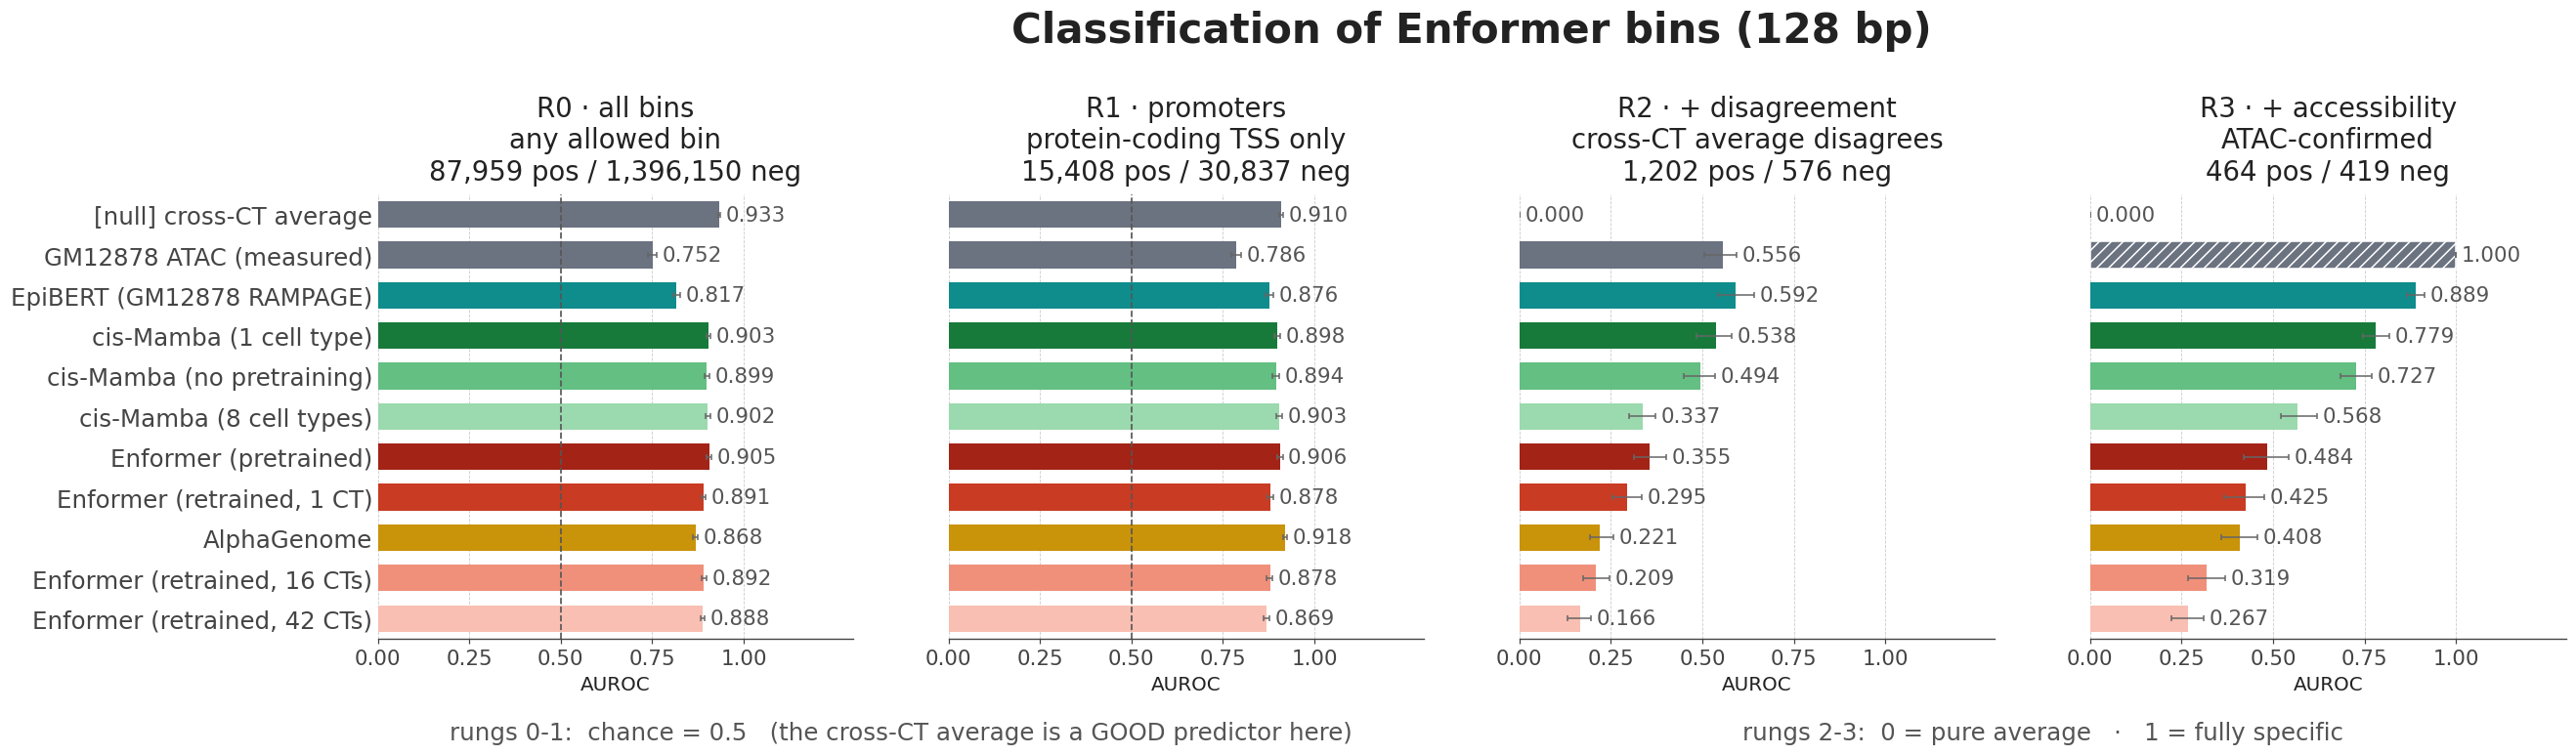

In [6]:
# ============================================================================
# §3 - the panel. Inlined from igvf_meeting_figures2_analysis._ladder_bars, minus
# its save() call: figures are for reading in the notebook.
# ============================================================================
ANCHOR_LO = 'chance = 0.5   (the cross-CT average is a GOOD predictor here)'
# Rungs 2-3 are scaled between two anchors that are not a chance line, so 0.5 has no
# direct reading on them. It is neither labelled nor drawn there.
ANCHOR_HI = '0 = pure average   ·   1 = fully specific'


def ladder_bars(df, rungs, grid_title, order_by_rung=-1, show_anchor_footnote=True):
    """Four ranked panels, one per rung, rows in a single shared order."""
    # The registry decides what is drawn, so a `hidden` arm stays in the cache and
    # never reaches the panel.
    drawable = {a.id for a in ARMS if not a.hidden}
    df = df[df.arm.isin(drawable)]
    fam = {a: BY_ID[a].family for a in df.arm.unique()}
    d_last = df[df.rung_i == (len(rungs) - 1 if order_by_rung == -1 else order_by_rung)]
    refs = [a for a in d_last.arm if fam[a] == 'reference']
    models = d_last[[fam[a] != 'reference' for a in d_last.arm]] \
        .sort_values('auroc', ascending=False).arm.tolist()
    order = list(dict.fromkeys(refs)) + models

    fig, axes = plt.subplots(1, len(rungs), figsize=(6.0 * len(rungs), 5.9), sharey=True)
    for ax, (r_i, rung) in zip(np.atleast_1d(axes), enumerate(rungs)):
        d = df[df.rung_i == r_i].set_index('arm').loc[order].reset_index()
        bc = d['by_construction'].to_numpy() if 'by_construction' in d \
            else np.zeros(len(d), bool)
        y = np.arange(len(d))
        bars = ax.barh(y, d.auroc, height=0.66, color=[color(a) for a in d.arm], zorder=3,
                       xerr=np.vstack([np.nan_to_num(d.auroc - d.lo),
                                       np.nan_to_num(d.hi - d.auroc)]),
                       error_kw=dict(ecolor='#666666', lw=1.0, capsize=2.2))
        for bar, flag in zip(bars, bc):
            if flag:
                bar.set_hatch('///')
                bar.set_edgecolor('white')
        for yi, (v, h) in enumerate(zip(d.auroc, d.hi)):
            ax.text((v if np.isnan(h) else h) + 0.015, yi, f'{v:.3f}', va='center',
                    ha='left', fontsize=14, color=INK2)
        # Only rungs 0-1 are ordinary discrimination, where 0.5 is chance.
        if r_i < 2:
            ax.axvline(0.5, ls='--', lw=1.1, color=INK2, zorder=4)
        ax.set_yticks(y)
        ax.set_yticklabels([label(a) for a in d.arm], fontsize=16)
        ax.set_ylim(len(order) - 0.5, -0.5)     # not invert_yaxis(): sharey would undo it
        ax.set_xlim(0, 1.30)
        ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
        subtitle = 'cross-CT average disagrees' if r_i == 2 else rung['subtitle']
        ax.set_title(f"{rung['name']}\n{textwrap.fill(subtitle, 34)}\n"
                     f"{rung['n_pos']:,} pos / {rung['n_neg']:,} neg", fontsize=18, pad=10)
        ax.set_xlabel('AUROC', fontsize=13)
        ax.tick_params(axis='x', labelsize=14)
        ax.grid(axis='x', ls='--', lw=0.55, color='#CCCCCC', zorder=0)
        ax.set_axisbelow(True)
        ax.tick_params(axis='y', length=0)
        ax.spines['left'].set_visible(False)
    # Extra breathing room between the four rung panels -- there is width to spare.
    fig.tight_layout(w_pad=4.5)
    fig.subplots_adjust(left=0.145, right=0.9931, wspace=0.20)
    # Title and footnotes centered on the actual column block, computed from the
    # axes' final positions rather than a literal x=0.5 -- the pinned margins mean
    # the columns no longer start near the canvas edge, so centering on the canvas
    # no longer centers on the panels.
    col_l, col_r = axes[0].get_position().x0, axes[-1].get_position().x1
    fig.text((col_l + col_r) / 2, 1.055, grid_title, ha='center', fontsize=27.5,
             fontweight='bold', color=INK)
    if show_anchor_footnote:
        mid_lo = (axes[0].get_position().x0 + axes[1].get_position().x1) / 2
        mid_hi = (axes[2].get_position().x0 + axes[-1].get_position().x1) / 2
        fig.text(mid_lo, -0.045, 'rungs 0-1:  ' + ANCHOR_LO, ha='center', fontsize=16,
                 color=INK2)
        fig.text(mid_hi, -0.045, 'rungs 2-3:  ' + ANCHOR_HI, ha='center', fontsize=16,
                 color=INK2)
    return fig


fig = ladder_bars(LAD, RUNGS_META, 'Classification of Enformer bins (128 bp)')
plt.show()

---
## 4. What moved

The eleven cached arms are unchanged — same numbers figure 3b prints — so the only thing to read
here is where the new arm lands.

The cell below prints the R3 ordering with and without EpiBERT, which is the ordering the panel's
rows are in.

In [7]:
# ============================================================================
# §4 - the R3 ordering, cached arms vs. with EpiBERT spliced in.
# ============================================================================
r3 = LAD[(LAD.rung_i == 3) & LAD.arm.isin({a.id for a in ARMS if not a.hidden})]
r3 = r3.sort_values('auroc', ascending=False)
out = pd.DataFrame({
    'arm': [label(a) for a in r3.arm],
    'family': [BY_ID[a].family for a in r3.arm],
    'R3 AUROC': r3.auroc.round(3).to_numpy(),
    '95% CI': [f'[{lo:.3f}, {hi:.3f}]' for lo, hi in zip(r3.lo, r3.hi)],
    'new': ['<--' if a == 'epibert' else '' for a in r3.arm],
})
out.reset_index(drop=True)

,arm,family,R3 AUROC,95% CI,new
0,GM12878 ATAC (measured),reference,1.000,"[1.000, 1.000]",
1,EpiBERT (GM12878 RAMPAGE),epibert,0.889,"[0.865, 0.913]",<--
2,cis-Mamba (1 cell type),ours,0.779,"[0.745, 0.817]",
3,cis-Mamba (no pretraining),ours,0.727,"[0.684, 0.769]",
4,cis-Mamba (8 cell types),ours,0.568,"[0.520, 0.620]",
5,Enformer (pretrained),enformer,0.484,"[0.419, 0.542]",
6,"Enformer (retrained, 1 CT)",enformer,0.425,"[0.366, 0.477]",
7,AlphaGenome,alphagenome,0.408,"[0.359, 0.456]",
8,"Enformer (retrained, 16 CTs)",enformer,0.319,"[0.267, 0.368]",
9,"Enformer (retrained, 42 CTs)",enformer,0.267,"[0.222, 0.311]",


---
## 5. Restrict to EpiBERT's 1,840 regions, then replace CAGE labels with RAMPAGE

These cells add two **fully rescored** ladders: (A) the original CAGE definitions on the
1,840 EpiBERT non-TSS test windows, and (B) GM12878 activity **and** the leave-GM12878-out
average defined using **measured RAMPAGE** on those same windows. No cached AUROCs are reused.
The original cells and their results above are preserved.

The 1,840 rows are selected by removing the 97 Enformer test windows whose 524,288-bp
contexts overlap EpiBERT's supplied training intervals. All 1,840 also pass the original
notebook's weaker overlap filter. Model outputs stay on the central 896 × 128-bp Enformer grid.

RAMPAGE inputs come from `EpiBERT/data/RAMPAGE_test/non_TSS` (not the TSS-recentered set).
Every record in all 50 files is identified by its **full DNA sequence**, checked against hg38,
and reordered into Enformer BED order. The supplementary dataset table identifies
`ENCFF415FEC_RAMPAGE_100.tfr` as GM12878 (RAMPAGE accession `ENCFF520YOP`).
The null is an equally weighted average of the **other 49 datasets**, excluding GM12878.
This is dataset weighting: repeated tissues/donors can contribute separately.

The released signals are already library-normalized 128-bp sums. We use those raw stored
values, without EpiBERT's square-root transform or smoothing. Activity is **positive signal
at or above the median of nonzero GM12878 RAMPAGE bins** over these regions; silence is **zero
measured signal**. This is an exploratory activity definition, not a calibrated detection
limit or a formal peak caller. About 98.7% of bins are zero, so an all-bin p95 would be zero. Nonzero-bin p25/p50/p75/p90/p95/p99 sensitivity is shown below. The initial p95 cutoff leaves no R2/R3 positive bins; p50 gives a nonempty primary comparison, without changing the disagreement definition or consulting model scores. Empty sensitivity comparisons are reported as undefined. The CAGE control keeps
its original ≥1.0 / <0.2 cutoffs. Promoter, cross-dataset disagreement, and ATAC restrictions
are otherwise retained, with quantiles recalculated on the 1,840-region subset.

Three chromosome-edge records have shifted 128-bp grids. Only those rows use
**overlap-weighted rebinning**, assuming uniform signal within each source bin; a sensitivity
check removes them. The other 1,837 rows align exactly. All intermediate artifacts and results
are saved under `EpiBERT/data/rampage_ladder_1840`; the original figure cache is untouched.

Interpretation: these are **bin-level** AUROCs. A low average among 49 datasets does not prove
absence in every other cell type. EpiBERT was trained for RAMPAGE and uses measured ATAC,
whereas most comparison arms predict CAGE; R3 also selects on accessibility. This is an assay
transfer comparison, not a controlled comparison of architectures. The null's R2/R3 AUROC
is zero by selection; random rankings still have expected AUROC 0.5 on every rung.

In [3]:
# §5a — load aligned measurements and the common subset; definitions above supply the engine.
import subprocess
from IPython.display import display
RP_ROOT = Path('/data1/lesliec/sarthak/EpiBERT')
RP_WORK = RP_ROOT / 'data/rampage_ladder_1840'
RP_DATA = Path('/data1/lesliec/sarthak/data')
RP_MO = RP_DATA / 'joint_playground/model_out'
if not (RP_WORK / 'aligned_rampage.npz').exists():
    subprocess.run([str(RP_ROOT / '.pixi/envs/default/bin/python'), '-u',
                    str(RP_WORK / 'build_inputs.py')], check=True)
RP_INFO = json.loads((RP_WORK / 'provenance.json').read_text())
# Prevent silently reusing a cache after any downloaded file changes.
for item in RP_INFO['inputs']:
    stat = Path(item['path']).stat()
    assert stat.st_size == item['size'] and stat.st_mtime_ns == item['mtime_ns'],         'RAMPAGE input changed: rerun build_inputs.py'
RP_REGIONS = pd.read_csv(RP_WORK / 'regions.tsv', sep='\t')
RP_DATASETS = pd.read_csv(RP_WORK / 'datasets.tsv', sep='\t')
with np.load(RP_WORK / 'aligned_rampage.npz') as cache:
    RP_ROWS = cache['enformer_rows'].copy()
    RP_TRUE = cache['gm12878'].copy()
    RP_AVG = cache['other_average'].copy()
    RP_EDGE = cache['edge_shifted'].copy()
assert RP_TRUE.shape == RP_AVG.shape == (1840, 896)
assert RP_DATASETS.sequence_multiset_verified.all() and len(RP_DATASETS) == 50
assert RP_REGIONS.enformer_row.tolist() == RP_ROWS.tolist()
RP_BED = pd.read_csv(RP_DATA / 'DK_zarr/sequences_enformer.bed', sep='\t', header=None)
RP_TEST_BED = RP_BED[RP_BED.iloc[:, -1] == 'test'].reset_index(drop=True)
assert np.array_equal(RP_TEST_BED.iloc[RP_ROWS, :3].to_numpy(),
                      RP_REGIONS[['chrom','start','end']].to_numpy())
RP_CAGE_FULL = np.asarray(np.load(RP_MO / 'GM12878_base_targets_conv.npy'), np.float32)
assert RP_CAGE_FULL.shape == (1937, 896)
# Only the channel count is needed; read local Zarr v2 metadata directly.
RP_LABEL_SHAPE = json.loads((RP_DATA / 'enformer/data/labels.zarr/test/.zarray').read_text())['shape']
assert RP_LABEL_SHAPE[:2] == [1937, 896]
RP_NCAGE = RP_LABEL_SHAPE[2] - 4675
RP_CAGE = RP_CAGE_FULL[RP_ROWS]
RP_CAGE_AVG = np.clip((np.load(RP_DATA / 'enformer/data/avg_cage_test_all.npy')[RP_ROWS]
                      * RP_NCAGE - RP_CAGE) / (RP_NCAGE - 1), 0, None)
RP_ATAC = np.load(RP_DATA / 'enformer/data/GM12878_ATAC_WW_denoised.npz')['test'][RP_ROWS, :, 0]
RP_BIN = 128
RP_T = 896
RP_RID = np.repeat(np.arange(1840), RP_T)
RP_CENTERS = RP_REGIONS.output_start.to_numpy()[:, None] + (np.arange(RP_T)+0.5)[None, :]*RP_BIN
sys.path.insert(0, '/data1/lesliec/sarthak/caduceus')
from evals.plotting_utils import GeneAnnotation
RP_GENES = GeneAnnotation(cache_dir=str(RP_DATA / 'DE_danwei')).df

In [4]:
def rp_tss_mask(chroms, centers, gene_df, strand=None, pad=500):
    """Boolean (n_region, n_bin): is this bin within `pad` bp of a protein-coding TSS."""
    df = gene_df[gene_df['feature'] == 'transcript']
    if strand is not None:
        df = df[df['strand'] == strand]
    by_chrom = {}
    for ch, g in df.groupby('chrom'):
        p = np.where(g['strand'].to_numpy() == '+', g['start0'].to_numpy(), g['end0'].to_numpy())
        by_chrom[str(ch)] = np.sort(p)
    out = np.zeros(centers.shape, bool)
    for ch in np.unique(chroms):
        arr = by_chrom.get(ch)
        if arr is None or arr.size == 0:
            continue
        rows = np.flatnonzero(chroms == ch)
        c = centers[rows]
        i = np.searchsorted(arr, c)
        lo = arr[np.clip(i - 1, 0, arr.size - 1)]
        hi = arr[np.clip(i, 0, arr.size - 1)]
        out[rows] = np.minimum(np.abs(c - lo), np.abs(c - hi)) <= pad
    return out


RP_TSS = rp_tss_mask(RP_REGIONS.chrom.to_numpy(), RP_CENTERS, RP_GENES, pad=500)
print(f'{len(RP_ROWS):,} regions; {RP_TSS.sum():,} promoter bins; '
      f'{RP_EDGE.sum()} chromosome-edge rows rebinned')
print('GM12878:', RP_INFO['gm12878']['file'])
print('Other datasets in RAMPAGE average:', RP_INFO['n_other_datasets'])
display(pd.DataFrame({'percentile': [50, 90, 95, 99, 100],
                      'all-bin RAMPAGE': np.percentile(RP_TRUE, [50, 90, 95, 99, 100]),
                      'nonzero-bin RAMPAGE': np.percentile(RP_TRUE[RP_TRUE>0], [50, 90, 95, 99, 100])}))
print(f'Zero-signal GM12878 bins: {(RP_TRUE == 0).mean():.1%}')
display(RP_DATASETS[['dataset_name','file_accession','rampage_accession','n_records']])

1,840 regions; 54,639 promoter bins; 3 chromosome-edge rows rebinned
GM12878: /data1/lesliec/sarthak/EpiBERT/data/RAMPAGE_test/non_TSS/ENCFF415FEC_RAMPAGE_100.tfr
Other datasets in RAMPAGE average: 49
Zero-signal GM12878 bins: 98.7%


,percentile,all-bin RAMPAGE,nonzero-bin RAMPAGE
0,50,0.000000,0.994342
1,90,0.000000,10.937763
2,95,0.000000,46.293254
3,99,0.331447,519.597422
4,100,99498.679688,99498.679688


,dataset_name,file_accession,rampage_accession,n_records
0,HG_uterus_F_59_years,ENCFF018NLH,ENCFF530XDO,1840
1,HG_body_of_pancreas_F_51_years,ENCFF063BAJ,ENCFF078YOS,1840
2,HG_heart_left_ventricle_F_53_years,ENCFF097EXD,ENCFF022TAW,1840
3,HG_breast_epithelium_F_51_years,ENCFF112BEA,ENCFF177FDJ,1840
4,HG_right_atrium_auricular_region_F_51_years,ENCFF122ENK,ENCFF428WTD,1840
5,HG_gastrocnemius_medialis_F_51_years,ENCFF125LEJ,ENCFF140IFV,1840
6,karpas_422,ENCFF129NJO,ENCFF129NJO,1840
7,HG_spleen_F_51_years,ENCFF159BUD,ENCFF514UNF,1840
8,HG_sigmoid_colon_M_54_years,ENCFF182ZGK,ENCFF539UPX,1840
9,HG_right_lobe_of_liver_F_53_years,ENCFF205LVV,ENCFF905UWL,1840


In [5]:
# §5b — source predictions for ALL arms. Every ladder below is rescored from these arrays.
RP_PRED = {}
def rp_add_prediction(arm, prediction, target=None):
    prediction = np.asarray(prediction, dtype=np.float32)
    if prediction.ndim == 3 and prediction.shape[-1] == 1:
        prediction = prediction[:, :, 0]
    assert prediction.shape == (1937, 896), (arm, prediction.shape)
    assert np.isfinite(prediction).all(), arm
    if target is not None:
        target = np.asarray(target, dtype=np.float32)
        if target.ndim == 3 and target.shape[-1] == 1:
            target = target[:, :, 0]
        assert np.allclose(target, RP_CAGE_FULL, rtol=1e-5, atol=1e-6), arm
    RP_PRED[arm] = prediction[RP_ROWS].copy()

for arm, stem in [('mamba_1ct', 'GM12878_no_mlm'), ('mamba_nopre', 'nopretrain'),
                  ('mamba_8ct', 'immune_CAGE')]:
    rp_add_prediction(arm, np.load(RP_MO / f'{stem}_predictions.npy', mmap_mode='r'),
                       np.load(RP_MO / f'{stem}_targets.npy', mmap_mode='r'))
rp_add_prediction('enformer_pre', np.load(RP_MO / 'enformer_test_track5110.npy'))
rp_add_prediction('alphagenome', np.load(RP_MO / 'alphagenome_cage_test_128bp.npy',
                                        mmap_mode='r')[:, :, 156])
for arm, stem in [('enformer_n1', 'enformer_retrained_gm12878'),
                  ('enformer_n1_1536', 'enformer_retrained_n1_1536'),
                  ('enformer_n16', 'enformer_retrained_n16'),
                  ('enformer_n42', 'enformer_retrained_n42')]:
    folder = RP_MO / stem
    pred = np.load(folder / f'{stem}_cage_predictions.npy', mmap_mode='r')
    target = np.load(folder / f'{stem}_cage_targets.npy', mmap_mode='r')
    if pred.ndim == 3:
        tracks = pd.read_csv(folder / f'{stem}_cage_tracks.csv')
        track = tracks[(tracks.cell_type == 'GM12878') & (tracks.assay == 'cage')]
        assert len(track) == 1 and int(track.target_index.iloc[0]) == 5110
        col = int(track.column.iloc[0])
        pred, target = pred[:, :, col], target[:, :, col]
    rp_add_prediction(arm, pred, target)
# Generated by EpiBERT/predict_rampage_test.py, which preserves all 1937 BED rows.
rp_add_prediction('epibert', np.load(RP_MO / 'epibert_gm12878_rampage_test_outputs.npy'))
assert set(RP_PRED) == {a.id for a in ARMS if a.family != 'reference'}
print(f'{len(RP_PRED)} model arms loaded on the same {RP_TRUE.shape} grid')

10 model arms loaded on the same (1840, 896) grid


In [6]:
# §5c — two separate label definitions, on exactly the same common regions.
RP_ACTIVE_PERCENTILE = 50

def rp_make_ladder(truth, average, *, assay, active_percentile=50, exclude_edges=False):
    allowed = np.repeat(~RP_EDGE if exclude_edges else np.ones(1840, bool), RP_T)
    tv, av, ac, ts = truth.ravel(), average.ravel(), RP_ATAC.ravel(), RP_TSS.ravel()
    assert all(np.isfinite(v).all() for v in (tv, av, ac))
    active_threshold = (1.0 if assay == 'CAGE' else float(np.percentile(tv[allowed & (tv > 0)], active_percentile)))
    # Quantile ties may include more than the nominal fraction; report actual counts.
    positive = allowed & (tv >= active_threshold) & (tv > 0)
    negative = allowed & ((tv < 0.2) if assay == 'CAGE' else (tv == 0))
    median, high = np.percentile(av[allowed & ts], [50, 90])
    low = av < median
    if median == 0:
        low = av == 0   # Include tied zeros rather than silently creating an empty R2.
    assert high > median, 'Cross-dataset average does not separate p50 and p90'
    open_threshold = float(np.percentile(ac[allowed], 95))
    masks = [(positive, negative),
             (positive & ts, negative & ts),
             (positive & ts & low, negative & ts & (av >= high)),
             (positive & ts & low & (ac >= open_threshold),
              negative & ts & (av >= high) & (ac < open_threshold))]
    names = ['R0 · all bins', 'R1 · promoters', 'R2 · + disagreement', 'R3 · + accessibility']
    subtitles = ['all 1,840 retained regions' if not exclude_edges else '1,837 exact-grid regions',
                 'protein-coding TSS ±500 bp', f'other-dataset {assay} average disagrees', 'ATAC-confirmed']
    rungs = []
    for i, ((pm, nm), name, subtitle) in enumerate(zip(masks, names, subtitles)):
        assert not (pm & nm).any(), f'Overlapping {assay} {name}'
        if i:
            assert not (pm & ~masks[i-1][0]).any() and not (nm & ~masks[i-1][1]).any()
        if pm.any() and nm.any():
            rungs.append(make_rung(name, subtitle, pm, nm, RP_RID))
        else:
            # Sensitivity cutoffs can leave no cases; AUROC is then undefined.
            rungs.append(dict(name=name, subtitle=subtitle, n_pos=int(pm.sum()), n_neg=int(nm.sum()),
                              n_preg=len(np.unique(RP_RID[pm])), n_nreg=len(np.unique(RP_RID[nm])),
                              pi=np.flatnonzero(pm), ni=np.flatnonzero(nm)))
    thresholds = dict(assay=assay, active_threshold=active_threshold,
                      silent_rule='<0.2' if assay == 'CAGE' else '==0',
                      activity_quantile_population='nonzero GM12878 bins' if assay == 'RAMPAGE' else 'fixed CAGE cutoff',
                      other_promoter_p50=float(median), other_promoter_p90=float(high),
                      atac_p95=open_threshold, n_regions=int(allowed.sum()/RP_T))
    return rungs, masks, thresholds

RP_CAGE_RUNGS, RP_CAGE_MASKS, RP_CAGE_THRESHOLDS = rp_make_ladder(RP_CAGE, RP_CAGE_AVG, assay='CAGE')
RP_RUNGS, RP_MASKS, RP_THRESHOLDS = rp_make_ladder(RP_TRUE, RP_AVG, assay='RAMPAGE',
                                                active_percentile=RP_ACTIVE_PERCENTILE)
assert all(r['n_pos'] and r['n_neg'] for r in RP_RUNGS + RP_CAGE_RUNGS)
display(pd.DataFrame([RP_CAGE_THRESHOLDS, RP_THRESHOLDS]))
RP_COUNTS = pd.DataFrame([dict(assay=assay, rung=r['name'],
                             **{k:r[k] for k in ('n_pos','n_neg','n_preg','n_nreg')})
                         for assay,rungs in [('CAGE', RP_CAGE_RUNGS), ('RAMPAGE', RP_RUNGS)]
                         for r in rungs])
display(RP_COUNTS)
RP_LABEL_OVERLAP = []
for i in [2, 3]:
    cage_positive, rampage_positive = RP_CAGE_MASKS[i][0], RP_MASKS[i][0]
    RP_LABEL_OVERLAP.append(dict(rung=f'R{i}', CAGE_positive=int(cage_positive.sum()),
                                RAMPAGE_positive=int(rampage_positive.sum()),
                                shared_positive=int((cage_positive & rampage_positive).sum()),
                                Jaccard=float((cage_positive & rampage_positive).sum()
                                              / (cage_positive | rampage_positive).sum())))
display(pd.DataFrame(RP_LABEL_OVERLAP))
RP_COUNTS.to_csv(RP_WORK / 'rung_counts.tsv', sep='\t', index=False)
_ = (RP_WORK / 'thresholds.json').write_text(json.dumps([RP_CAGE_THRESHOLDS,RP_THRESHOLDS], indent=2))

,assay,active_threshold,silent_rule,activity_quantile_population,other_promoter_p50,other_promoter_p90,atac_p95,n_regions
0,CAGE,1.000000,<0.2,fixed CAGE cutoff,0.134048,2.387907,9.63809,1840
1,RAMPAGE,0.994342,==0,nonzero GM12878 bins,0.146341,3.229097,9.63809,1840


,assay,rung,n_pos,n_neg,n_preg,n_nreg
0,CAGE,R0 · all bins,85798,1364476,1840,1840
1,CAGE,R1 · promoters,15145,30334,928,1099
2,CAGE,R2 · + disagreement,1186,570,469,278
3,CAGE,R3 · + accessibility,455,416,229,214
4,RAMPAGE,R0 · all bins,10928,1626786,928,1840
5,RAMPAGE,R1 · promoters,5480,46093,662,1105
6,RAMPAGE,R2 · + disagreement,293,1976,175,531
7,RAMPAGE,R3 · + accessibility,231,1567,147,462


,rung,CAGE_positive,RAMPAGE_positive,shared_positive,Jaccard
0,R2,1186,293,24,0.016495
1,R3,455,231,22,0.033133


In [7]:
# §5d — retain the original 200-draw region bootstrap and seed for comparability.
def rp_score_all(rungs, average, assay, n_boot=N_BOOT):
    predictions = {**RP_PRED, 'null_avg': average, 'acc_atac': RP_ATAC}
    rows = []
    for arm, prediction in predictions.items():
        for i, rung in enumerate(rungs):
            auc, lo, hi = score_rung(prediction.ravel(), rung, n_boot=n_boot,
                                    seed=BOOT_SEED + 1000*i)
            rows.append(dict(assay=assay, arm=arm, rung=rung['name'], rung_i=i,
                             auroc=auc, lo=lo, hi=hi,
                             by_construction=(arm=='acc_atac' and i==3)))
        print(f'{assay}: {arm}', flush=True)
    result = pd.DataFrame(rows)
    assert np.allclose(result[(result.arm=='null_avg') & (result.rung_i>=2)].auroc, 0)
    assert np.allclose(result[result.by_construction].auroc, 1)
    return result

RP_LAD_CAGE = rp_score_all(RP_CAGE_RUNGS, RP_CAGE_AVG, 'CAGE')
RP_LAD_RAMPAGE = rp_score_all(RP_RUNGS, RP_AVG, 'RAMPAGE')
RP_RESULTS = pd.concat([RP_LAD_CAGE, RP_LAD_RAMPAGE], ignore_index=True)
RP_RESULTS.to_csv(RP_WORK / 'ladder_results.tsv', sep='\t', index=False)
display(RP_RESULTS.pivot(index='arm', columns=['assay','rung_i'], values='auroc').round(3))

CAGE: mamba_1ct
CAGE: mamba_nopre
CAGE: mamba_8ct
CAGE: enformer_pre
CAGE: alphagenome
CAGE: enformer_n1
CAGE: enformer_n1_1536
CAGE: enformer_n16
CAGE: enformer_n42
CAGE: epibert
CAGE: null_avg
CAGE: acc_atac
RAMPAGE: mamba_1ct
RAMPAGE: mamba_nopre
RAMPAGE: mamba_8ct
RAMPAGE: enformer_pre
RAMPAGE: alphagenome
RAMPAGE: enformer_n1
RAMPAGE: enformer_n1_1536
RAMPAGE: enformer_n16
RAMPAGE: enformer_n42
RAMPAGE: epibert
RAMPAGE: null_avg
RAMPAGE: acc_atac


assay              CAGE                      RAMPAGE                     
rung_i                0      1      2      3       0      1      2      3
arm                                                                      
acc_atac          0.752  0.786  0.556  1.000   0.891  0.878  0.852  1.000
alphagenome       0.868  0.918  0.222  0.410   0.944  0.944  0.511  0.624
enformer_n1       0.879  0.858  0.238  0.357   0.912  0.879  0.401  0.485
enformer_n16      0.892  0.878  0.210  0.318   0.908  0.893  0.414  0.506
enformer_n1_1536  0.892  0.879  0.296  0.426   0.903  0.883  0.434  0.525
enformer_n42      0.889  0.869  0.166  0.266   0.914  0.893  0.413  0.518
enformer_pre      0.905  0.906  0.357  0.486   0.905  0.908  0.477  0.567
epibert           0.818  0.876  0.593  0.892   0.971  0.941  0.724  0.868
mamba_1ct         0.904  0.898  0.541  0.782   0.913  0.911  0.627  0.740
mamba_8ct         0.902  0.903  0.339  0.569   0.914  0.916  0.487  0.599
mamba_nopre       0.899  0.894  0.496  0.729   0.913  0.907  0.572  0.682
null_avg          0.933  0.909  0.000  0.000   0.936  0.902  0.000  0.000

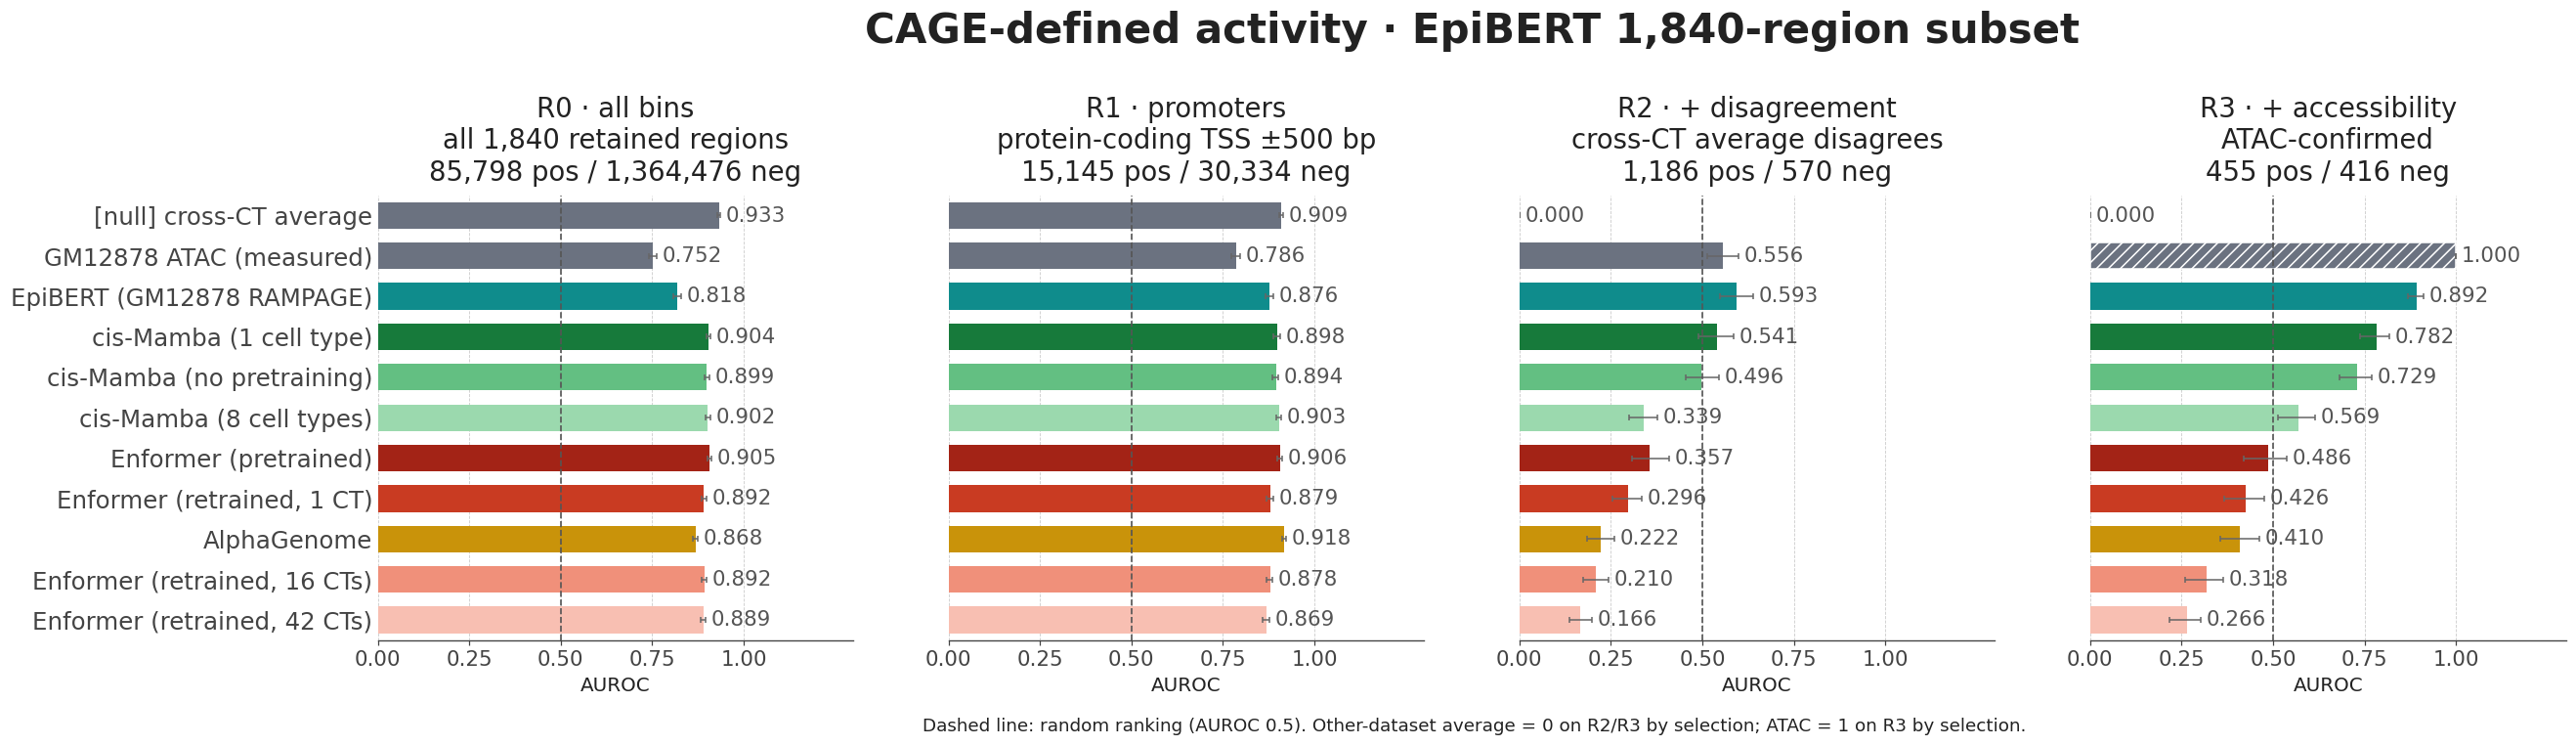

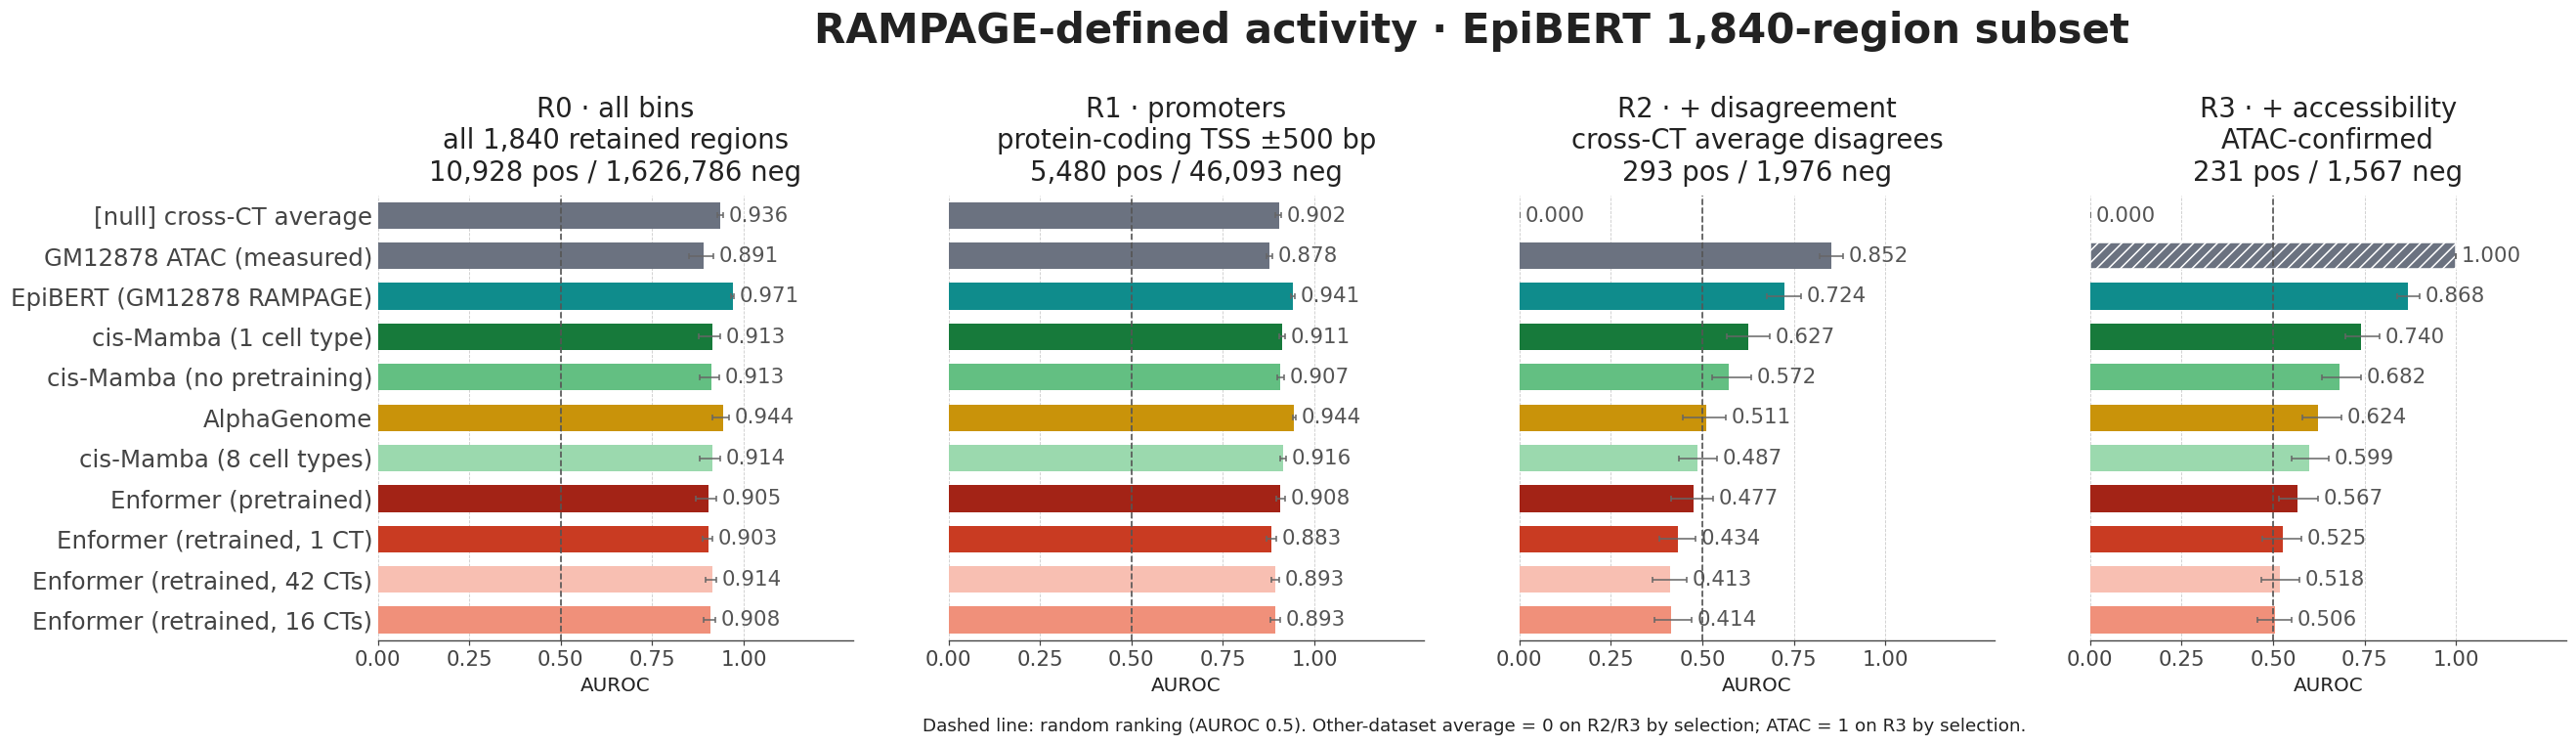

In [8]:
# §5e — the original plot style, with one figure per assay and honest AUROC guides.
for assay, result, rungs in [('CAGE', RP_LAD_CAGE, RP_CAGE_RUNGS),
                             ('RAMPAGE', RP_LAD_RAMPAGE, RP_RUNGS)]:
    figure = ladder_bars(result, rungs, f'{assay}-defined activity · EpiBERT 1,840-region subset',
                         show_anchor_footnote=False)
    for ax in figure.axes[2:]:
        ax.axvline(0.5, ls='--', lw=1.1, color=INK2, zorder=4)
    figure.text(0.57, -0.03, 'Dashed line: random ranking (AUROC 0.5). '
                'Other-dataset average = 0 on R2/R3 by selection; ATAC = 1 on R3 by selection.',
                ha='center', fontsize=12)
    figure.savefig(RP_WORK / f'ladder_{assay.lower()}_1840.png', dpi=150, bbox_inches='tight')
    plt.show()

In [9]:
# §5f — sensitivity to the activity threshold and to the 3 approximate edge rows.
# Point estimates only: the primary p50 result above carries bootstrap intervals.
RP_SENSITIVITY_ROWS = []
for percentile, omit_edges in [(25, False), (50, False), (75, False), (90, False), (95, False), (99, False), (50, True)]:
    rungs, masks, thresholds = rp_make_ladder(RP_TRUE, RP_AVG, assay='RAMPAGE',
                                              active_percentile=percentile, exclude_edges=omit_edges)
    for arm, prediction in {**RP_PRED, 'null_avg': RP_AVG, 'acc_atac': RP_ATAC}.items():
        for i in [2, 3]:
            estimable = bool(rungs[i]['n_pos'] and rungs[i]['n_neg'])
            auc = score_rung(prediction.ravel(), rungs[i], n_boot=0)[0] if estimable else np.nan
            RP_SENSITIVITY_ROWS.append(dict(active_percentile=percentile, omit_edges=omit_edges,
                                           active_threshold=thresholds['active_threshold'],
                                           n_regions=thresholds['n_regions'], arm=arm, rung_i=i,
                                           n_pos=rungs[i]['n_pos'], n_neg=rungs[i]['n_neg'], auroc=auc,
                                           status='estimated' if estimable else 'undefined: empty class'))
RP_SENSITIVITY = pd.DataFrame(RP_SENSITIVITY_ROWS)
RP_SENSITIVITY.to_csv(RP_WORK / 'threshold_sensitivity.tsv', sep='\t', index=False)
display(RP_SENSITIVITY[['active_percentile','omit_edges','rung_i','active_threshold','n_pos','n_neg','status']].drop_duplicates())
display(RP_SENSITIVITY.pivot(index='arm', columns=['active_percentile','omit_edges','rung_i'],
                            values='auroc').round(3))

# Export selected 128-bp bins, not merged/called peaks. Enformer row IDs remain explicit.
RP_SPECIFIC_TABLES = []
for rung_i in [2, 3]:
    for cls, mask in zip(['GM12878_active_other_average_low','GM12878_silent_other_average_high'],
                          RP_MASKS[rung_i]):
        row, bin_i = np.divmod(np.flatnonzero(mask), RP_T)
        starts = RP_REGIONS.output_start.to_numpy()[row] + bin_i*RP_BIN
        RP_SPECIFIC_TABLES.append(pd.DataFrame(dict(
            chrom=RP_REGIONS.chrom.to_numpy()[row], start=starts, end=starts+RP_BIN,
            rung=f'R{rung_i}', label=cls, enformer_row=RP_ROWS[row], bin_index=bin_i,
            gm12878_rampage=RP_TRUE[row,bin_i], other_average_rampage=RP_AVG[row,bin_i],
            gm12878_atac=RP_ATAC[row,bin_i], edge_rebinned=RP_EDGE[row])))
RP_SPECIFIC_BINS = pd.concat(RP_SPECIFIC_TABLES, ignore_index=True)
RP_SPECIFIC_BINS.to_csv(RP_WORK / 'rampage_specific_bins.tsv', sep='\t', index=False)
display(RP_SPECIFIC_BINS[RP_SPECIFIC_BINS.label=='GM12878_active_other_average_low']
        .sort_values('gm12878_rampage',ascending=False).head(20))
print('Results and selected-bin coordinates:', RP_WORK)

Results and selected-bin coordinates: /data1/lesliec/sarthak/EpiBERT/data/rampage_ladder_1840


,active_percentile,omit_edges,rung_i,active_threshold,n_pos,n_neg,status
0,25,False,2,0.331447,768,1976,estimated
1,25,False,3,0.331447,566,1567,estimated
24,50,False,2,0.994342,293,1976,estimated
25,50,False,3,0.994342,231,1567,estimated
48,75,False,2,2.320130,84,1976,estimated
49,75,False,3,2.320130,76,1567,estimated
72,90,False,2,10.937763,7,1976,estimated
73,90,False,3,10.937763,6,1567,estimated
96,95,False,2,46.293254,0,1976,undefined: empty class
97,95,False,3,46.293254,0,1567,undefined: empty class


active_percentile     25            50         ...    99         50       
omit_edges         False         False         ... False      True        
rung_i                 2      3      2      3  ...     2   3      2      3
arm                                            ...                        
acc_atac           0.828  1.000  0.852  1.000  ...   NaN NaN  0.854  1.000
alphagenome        0.441  0.565  0.511  0.624  ...   NaN NaN  0.512  0.622
enformer_n1        0.395  0.501  0.401  0.485  ...   NaN NaN  0.396  0.481
enformer_n16       0.391  0.499  0.414  0.506  ...   NaN NaN  0.409  0.502
enformer_n1_1536   0.416  0.523  0.434  0.525  ...   NaN NaN  0.430  0.521
enformer_n42       0.379  0.499  0.413  0.518  ...   NaN NaN  0.412  0.515
enformer_pre       0.430  0.530  0.477  0.567  ...   NaN NaN  0.474  0.563
epibert            0.690  0.854  0.724  0.868  ...   NaN NaN  0.727  0.866
mamba_1ct          0.578  0.711  0.627  0.740  ...   NaN NaN  0.625  0.738
mamba_8ct          0.448  0.577  0.487  0.599  ...   NaN NaN  0.484  0.595
mamba_nopre        0.534  0.664  0.572  0.682  ...   NaN NaN  0.570  0.679
null_avg           0.000  0.000  0.000  0.000  ...   NaN NaN  0.000  0.000

[12 rows x 14 columns]

,chrom,start,end,rung,label,enformer_row,bin_index,gm12878_rampage,other_average_rampage,gm12878_atac,edge_rebinned
2272,chr14,78403649,78403777,R3,GM12878_active_other_average_low,63,492,45.342033,0.024847,33.147064,False
5,chr14,78403649,78403777,R2,GM12878_active_other_average_low,63,492,45.342033,0.024847,33.147064,False
92,chr19,10105586,10105714,R2,GM12878_active_other_average_low,539,693,42.093826,0.013732,331.465271,False
2345,chr19,10105586,10105714,R3,GM12878_active_other_average_low,539,693,42.093826,0.013732,331.465271,False
97,chr3,190121816,190121944,R2,GM12878_active_other_average_low,545,817,26.515774,0.049001,1.410852,False
222,chr19,54662218,54662346,R2,GM12878_active_other_average_low,1513,234,20.881180,0.031498,54.038666,False
2441,chr19,54662218,54662346,R3,GM12878_active_other_average_low,1513,234,20.881180,0.031498,54.038666,False
2346,chr19,10105714,10105842,R3,GM12878_active_other_average_low,539,694,12.595005,0.000000,324.272400,False
93,chr19,10105714,10105842,R2,GM12878_active_other_average_low,539,694,12.595005,0.000000,324.272400,False
141,chrX,48683568,48683696,R2,GM12878_active_other_average_low,928,276,11.898959,0.066678,104.003395,False
